# Task 2: Modeling — E-commerce Fraud Data (`Fraud_Data.csv`)

Goal: build and compare a baseline (Logistic Regression) against an ensemble (LightGBM) on the e-commerce fraud data, evaluated on the **untouched, imbalanced test set**.

**Notebook map**
1. Load and sanity-check data
2. Metric selection
3. Baseline: Logistic Regression
4. Ensemble: LightGBM (SMOTE arm and class-weight arm)
5. Evaluation
6. Observations and save outputs

In [1]:
import os, sys, re
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

sys.path.append(str(PROJECT_ROOT / "src"))
from modeling_utils import evaluate_model, plot_pr_curves

RANDOM_STATE = 42

## 1. Load and sanity-check data
Only consuming the Task 1 outputs here. No feature regeneration.

In [2]:
fraud_resampled = joblib.load(DATA_DIR / "fraud_train_resampled.pkl")
fraud_split = joblib.load(DATA_DIR / "fraud_train_test_split.pkl")

X_train_fraud_res, y_train_fraud_res = fraud_resampled
X_train_fraud, X_test_fraud, y_train_fraud, y_test_fraud = fraud_split

In [3]:
print(f"Train (original):   {X_train_fraud.shape}")
print(f"Train (resampled):  {X_train_fraud_res.shape}")
print(f"Test:               {X_test_fraud.shape}")

Train (original):   (120889, 192)
Train (resampled):  (219136, 192)
Test:               (30223, 192)


In [4]:
def class_balance(y, label):
    rate = float(np.mean(y))
    print(f"{label}: fraud rate = {rate:.4%}  (n={len(y)})")
    return rate

res_rate = class_balance(y_train_fraud_res, "Train (resampled)")
orig_rate = class_balance(y_train_fraud, "Train (original)")
test_rate = class_balance(y_test_fraud, "Test")

# Resampled train must be ~50/50; test must keep the real-world imbalance
assert 0.45 <= res_rate <= 0.55, "Resampled train is not balanced as expected"
assert test_rate < 0.15, "Test set fraud rate looks off: check for leakage"

Train (resampled): fraud rate = 50.0000%  (n=219136)
Train (original): fraud rate = 9.3648%  (n=120889)
Test: fraud rate = 9.3637%  (n=30223)


In [5]:
print(X_train_fraud_res.dtypes.value_counts())
object_cols = X_train_fraud_res.select_dtypes(include="object").columns.tolist()
print(f"Remaining object columns: {object_cols}")
assert not object_cols, "Unencoded categorical columns remain"

# Train and test must expose identical columns in identical order
assert list(X_train_fraud_res.columns) == list(X_test_fraud.columns) == list(X_train_fraud.columns)

bool       185
float64      7
Name: count, dtype: int64
Remaining object columns: []


## 2. Metric selection
The test fraud rate is about 9.36%, so a model that always predicts "legit" scores about 90.6% accuracy. Accuracy is therefore **not used**.

- **Primary metric: PR-AUC** (average precision). It is threshold-free and focuses on the rare fraud class.
- **Secondary metrics:** precision, recall and F1 at the default 0.5 threshold, plus raw confusion-matrix counts.
- ROC-AUC is reported for reference only; it can look flattering when negatives dominate.
- **All metrics are computed on the untouched test set**, never on the SMOTE-resampled training data.
- Cost framing (assumption, not measured): a missed fraud (false negative) usually costs more than a false alarm (false positive). Section 5 shows both.

## 3. Baseline: Logistic Regression
Trained on the SMOTE-resampled data. No `class_weight` is set because SMOTE already balanced the classes; using both would double-correct the imbalance.

In [6]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train_fraud_res, y_train_fraud_res)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [7]:
# Interpretable reference point: largest coefficients by absolute value
coefs = pd.Series(logreg.coef_[0], index=X_train_fraud_res.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
top_coefs

country_United States         6.392482
country_Unknown               6.264506
country_China                 6.155439
country_Japan                 5.851280
country_United Kingdom        5.830999
country_Germany               5.568025
country_Italy                 5.522685
country_Brazil                5.477330
country_Korea Republic of     5.424024
country_Colombia              5.413397
country_Belgium               5.409972
country_France                5.365400
country_Canada                5.300082
country_Russian Federation    5.259600
country_Netherlands           5.211321
dtype: float64

## 4. Ensemble: LightGBM
Two arms, so we can tell whether SMOTE helped at all:
- **SMOTE arm:** trained on the resampled data.
- **Class-weight arm:** trained on the original data with `scale_pos_weight`.

LightGBM rejects some special characters in feature names (country names after one-hot encoding can contain them), so the LightGBM arms use copies with cleaned column names.

In [8]:
def clean_names(X):
    X = X.copy()
    X.columns = [re.sub(r"[^0-9a-zA-Z_]", "_", str(c)) for c in X.columns]
    assert X.columns.is_unique, "Column-name cleaning created duplicate names"
    return X

Xl_train_res = clean_names(X_train_fraud_res)
Xl_train = clean_names(X_train_fraud)
Xl_test = clean_names(X_test_fraud)

In [9]:
import lightgbm as lgb

lgbm_smote = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
)
lgbm_smote.fit(Xl_train_res, y_train_fraud_res)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [10]:
spw = (y_train_fraud == 0).sum() / (y_train_fraud == 1).sum()
print(f"scale_pos_weight = {spw:.2f}")

lgbm_weighted = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.05, scale_pos_weight=spw,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1,
)
lgbm_weighted.fit(Xl_train, y_train_fraud)

scale_pos_weight = 9.68


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,300
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## 5. Evaluation
Every model is scored on the real-distribution test set with the same function.

In [11]:
models = {
    "LogReg (SMOTE)":          (logreg,        X_test_fraud),
    "LightGBM (SMOTE)":        (lgbm_smote,    Xl_test),
    "LightGBM (class-weight)": (lgbm_weighted, Xl_test),
}

rows, probas = [], {}
for name, (m, Xte) in models.items():
    metrics, p = evaluate_model(name, m, Xte, y_test_fraud)
    rows.append(metrics)
    probas[name] = p

fraud_results = pd.DataFrame(rows).set_index("model")
fraud_results.round(4)

,pr_auc,roc_auc,precision,recall,f1,tp,fp,fn,tn
model,,,,,,,,,
LogReg (SMOTE),0.6307,0.8117,0.7508,0.5781,0.6532,1636,543,1194,26850
LightGBM (SMOTE),0.7080,0.8397,0.9740,0.5297,0.6862,1499,40,1331,27353
LightGBM (class-weight),0.7072,0.8372,0.5434,0.6943,0.6097,1965,1651,865,25742


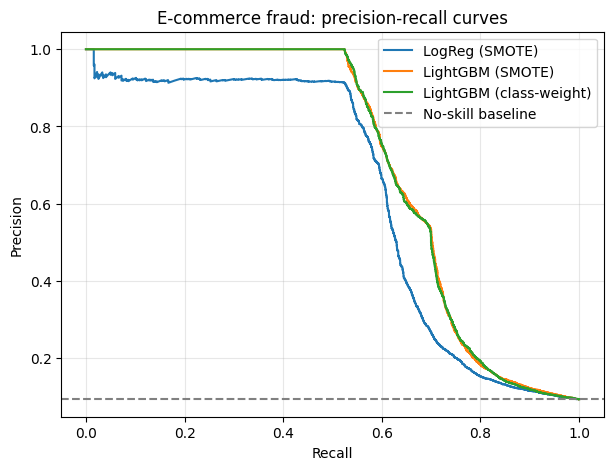

In [12]:
plot_pr_curves(y_test_fraud, probas, "E-commerce fraud: precision-recall curves")

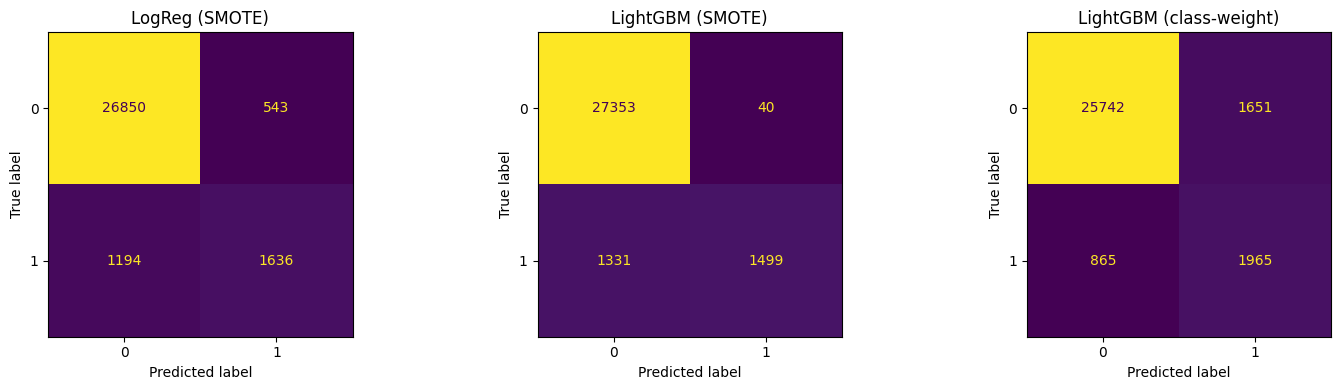

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(probas), figsize=(5 * len(probas), 4))
for ax, (name, p) in zip(axes, probas.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_fraud, (p >= 0.5).astype(int), ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Observations
*Fill this in after running the cells above. It feeds `model_comparison.ipynb`.*

- Best model by PR-AUC:
- SMOTE arm vs class-weight arm (did SMOTE help?):
- Gap between LogReg and LightGBM (large or small?):
- Precision/recall tradeoff at the 0.5 threshold:
- Any sign of overfitting to SMOTE-generated samples:

In [14]:
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

joblib.dump(logreg, MODELS_DIR / "fraud_logreg.pkl")
joblib.dump(lgbm_smote, MODELS_DIR / "fraud_lgbm_smote.pkl")
joblib.dump(lgbm_weighted, MODELS_DIR / "fraud_lgbm_weighted.pkl")
fraud_results.to_csv(RESULTS_DIR / "fraud_results.csv")
print("Saved models and results.")

Saved models and results.
